# Password fields and webpage size

Our research question asks which URL and webpage features phishing and legitimate websites share. Now we'll check whether that relationship changes when comparing pages with similar recorded sizes.

We use the PhiUSIIL dataset:
- `label = 0`: phishing
- `label = 1`: legitimate
- `HasPasswordField`: whether a password field was recorded
- `LineOfCode`: recorded webpage source-code line count

Each percentage uses all pages of that class within the size group as its denominator. Error bars show 95% Wilson confidence intervals. 

Password-field percentages and 95% Wilson intervals:


group,site_type,password_fields,total,percent,ci_low,ci_high
str,str,i64,i64,f64,f64,f64
"""Overall""","""Phishing""",5438,100945,5.39,5.25,5.53
"""Overall""","""Legitimate""",18675,134850,13.85,13.67,14.03
"""101–500""","""Phishing""",3827,22305,17.16,16.67,17.66
"""101–500""","""Legitimate""",925,24440,3.78,3.55,4.03
"""501–2,000""","""Phishing""",533,1036,51.45,48.4,54.48
"""501–2,000""","""Legitimate""",7883,74795,10.54,10.32,10.76
"""2,001–10,000""","""Phishing""",84,108,77.78,69.06,84.59
"""2,001–10,000""","""Legitimate""",8823,33052,26.69,26.22,27.17


Median recorded lines of code by classification:


label,median_lines
i64,f64
0,12.0
1,1105.0


Class counts for pages with 100 lines or fewer:


label,len
i64,u32
0,77492


... (6 outputs left out)

HTTPS from URL text


group,phishing_percent,legitimate_percent,difference_percentage_points
str,f64,f64,f64
"""Overall""",8.21,13.85,-5.64
"""101–500""",15.36,3.78,11.57
"""501–2,000""",53.91,10.54,43.37
"""2,001–10,000""",79.17,26.69,52.47


One row per URL


group,phishing_percent,legitimate_percent,difference_percentage_points
str,f64,f64,f64
"""Overall""",5.33,13.85,-8.52
"""101–500""",16.98,3.78,13.2
"""501–2,000""",51.46,10.54,40.92
"""2,001–10,000""",77.78,26.69,51.08


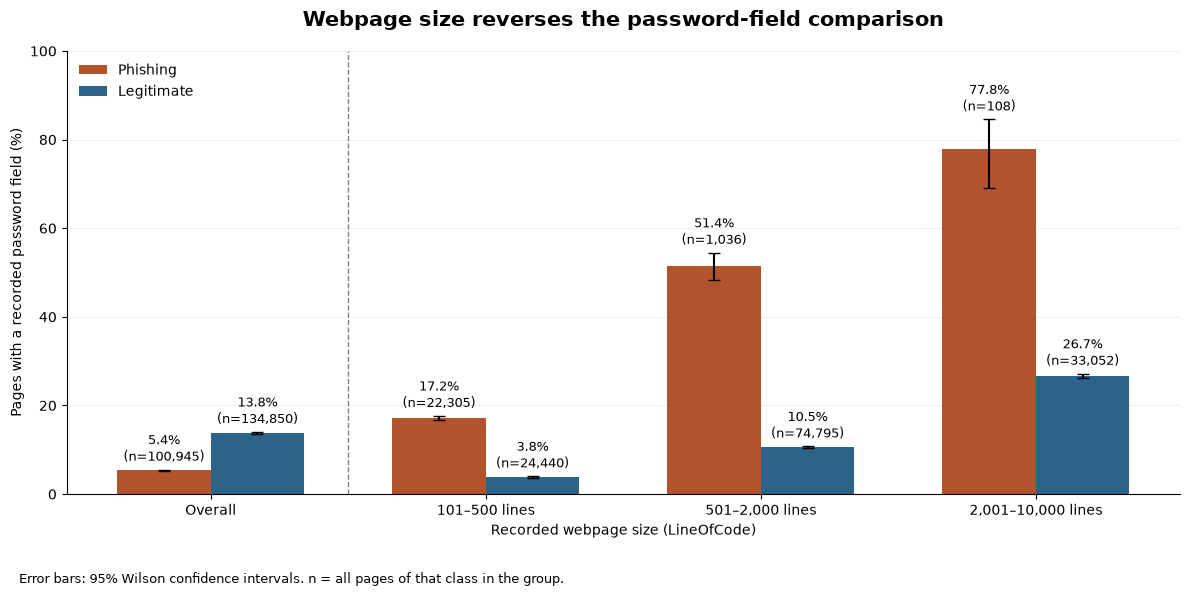

In [2]:
from pathlib import Path
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(10)
pl.Config.set_tbl_width_chars(140)

# Works from the repository root or notebooks folder.
root = Path.cwd()
if not (root / "datasets").exists():
    root = root.parent

df = pl.read_csv(
    root / "datasets/PhiUSIIL_Phishing_URL_Dataset.csv",
    columns=[
        "URL", "label", "HasPasswordField",
        "LineOfCode", "IsHTTPS"
    ]
)

def wilson_interval(count, total):
    """95% Wilson confidence interval, as percentages."""
    z = 1.959963984540054
    p = count / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = (
        z * np.sqrt(
            p * (1 - p) / total
            + z**2 / (4 * total**2)
        ) / denominator
    )
    return 100 * (center - margin), 100 * (center + margin)

def summarize(data):
    groups = [
        ("Overall", data),
        (
            "101–500",
            data.filter(pl.col("LineOfCode").is_between(101, 500))
        ),
        (
            "501–2,000",
            data.filter(pl.col("LineOfCode").is_between(501, 2000))
        ),
        (
            "2,001–10,000",
            data.filter(pl.col("LineOfCode").is_between(2001, 10000))
        )
    ]

    records = []

    for group_name, group in groups:
        for label, site_type in [
            (0, "Phishing"),
            (1, "Legitimate")
        ]:
            class_group = group.filter(pl.col("label") == label)
            total = class_group.height
            count = int(class_group["HasPasswordField"].sum())
            low, high = wilson_interval(count, total)

            records.append({
                "group": group_name,
                "site_type": site_type,
                "password_fields": count,
                "total": total,
                "percent": 100 * count / total,
                "ci_low": low,
                "ci_high": high
            })

    return pl.DataFrame(records)

summary = summarize(df)

print("Password-field percentages and 95% Wilson intervals:")
display(
    summary.with_columns(
        pl.col("percent", "ci_low", "ci_high").round(2)
    )
)

print("Median recorded lines of code by classification:")
display(
    df.group_by("label")
    .agg(
        pl.col("LineOfCode").median().alias("median_lines")
    )
    .sort("label")
)

# Check the sizes of the groups excluded from the main figure.
print("Class counts for pages with 100 lines or fewer:")
display(
    df.filter(pl.col("LineOfCode") <= 100)
    .group_by("label")
    .len()
    .sort("label")
)

print("Class counts for pages above 10,000 lines:")
display(
    df.filter(pl.col("LineOfCode") > 10000)
    .group_by("label")
    .len()
    .sort("label")
)

# Check whether HTTPS or repeated URLs explain the reversal.
checks = [
    ("All rows", df),
    (
        "Recorded HTTPS only",
        df.filter(pl.col("IsHTTPS") == 1)
    ),
    (
        "HTTPS from URL text",
        df.filter(
            pl.col("URL")
            .str.to_lowercase()
            .str.starts_with("https://")
        )
    ),
    (
        "One row per URL",
        df.unique(
            subset=["URL"],
            keep="first",
            maintain_order=True
        )
    )
]

for name, data in checks:
    check_summary = summarize(data)

    phishing = (
        check_summary
        .filter(pl.col("site_type") == "Phishing")
        .select(
            "group",
            pl.col("percent").alias("phishing_percent")
        )
    )

    legitimate = (
        check_summary
        .filter(pl.col("site_type") == "Legitimate")
        .select(
            "group",
            pl.col("percent").alias("legitimate_percent")
        )
    )

    comparison = (
        phishing.join(legitimate, on="group", how="left")
        .with_columns(
            (
                pl.col("phishing_percent")
                - pl.col("legitimate_percent")
            ).alias("difference_percentage_points")
        )
    )

    print(name)
    display(
        comparison.with_columns(
            pl.col(pl.Float64).round(2)
        )
    )

# Make the figure.
group_order = [
    "Overall", "101–500", "501–2,000", "2,001–10,000"
]

x = np.arange(len(group_order))
width = 0.34

fig, ax = plt.subplots(figsize=(12, 6))

for site_type, offset, color in [
    ("Phishing", -width / 2, "#B3532C"),
    ("Legitimate", width / 2, "#2C6389")
]:
    # summarize() creates rows in group_order.
    rows = summary.filter(pl.col("site_type") == site_type)

    percentages = rows["percent"].to_numpy()
    errors = np.vstack([
        percentages - rows["ci_low"].to_numpy(),
        rows["ci_high"].to_numpy() - percentages
    ])

    ax.bar(
        x + offset,
        percentages,
        width,
        label=site_type,
        color=color,
        yerr=errors,
        capsize=4
    )

    for position, row in zip(
        x + offset, rows.iter_rows(named=True)
    ):
        ax.text(
            position,
            row["ci_high"] + 2,
            f'{row["percent"]:.1f}%\n(n={row["total"]:,})',
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Webpage size reverses the password-field comparison",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xticks(
    x,
    [
        "Overall",
        "101–500 lines",
        "501–2,000 lines",
        "2,001–10,000 lines"
    ]
)

ax.set_ylabel("Pages with a recorded password field (%)")
ax.set_xlabel("Recorded webpage size (LineOfCode)")
ax.set_ylim(0, 100)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.02,
    0.02,
    "Error bars: 95% Wilson confidence intervals. "
    "n = all pages of that class in the group.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.07, 1, 1])

figure_folder = root / "figures"
figure_folder.mkdir(exist_ok=True)

fig.savefig(
    figure_folder / "password-fields-by-webpage-size.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()